In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 5)
print("Setup complete. Libraries loaded.")

Setup complete. Libraries loaded.


In [ ]:

## Part 1: Thinking Like a Tree

Imagine you're building an app that suggests something for a user to do, based only on two
things you know about them: **Gender** and **Occupation**.

| Gender | Occupation | Suggestion |
|---|---|---|
| F | Student | FIFA |
| F | Programmer | GitHub |
| M | Programmer | FACEBOOK |
| F | Programmer | GitHub |
| M | Student | FIFA |
| M | Student | FIFA |

Looking at this table, a human can spot the pattern pretty quickly:

```
if occupation == "Student":
    print("FIFA")
else:
    if gender == "Female":
        print("GitHub")
    else:
        print("FACEBOOK")
```

This *is* a decision tree — a nested set of if/else questions learned from data. Below is the
same logic drawn as a tree:

```
                Is Occupation == Student?
                 /Yes                \No
              FIFA              Is Gender == Female?
                                  /Yes         \No
                              GitHub        FACEBOOK
```

### TODO 1.1 — Implement the rule above as a function

Complete the function below so that it reproduces the table exactly.


In [14]:
def suggest_app(gender, occupation):
    if occupation == "Student":
        return "FIFA"
    else:
        if gender == "F":
            return "GitHub"
        else:
            return "FACEBOOK"
            
    #-suggest_app("Male", "student")
    pass

In [7]:
tests = [
    ("F", "Student", "FIFA"),
    ("M", "Student", "FIFA"),
    ("F", "Programmer", "GitHub"),
    ("M", "Programmer", "Facebook"),
]

for gender, occ, expected in tests:
    result = suggest_app(gender, occ)
    status = "PASS" if result == expected else "FAIL"
    print(f"{status}: suggest_app({gender!r}, {occ!r}) -> {result} (expected {expected})")


PASS: suggest_app('F', 'Student') -> FIFA (expected FIFA)
PASS: suggest_app('M', 'Student') -> FIFA (expected FIFA)
PASS: suggest_app('F', 'Programmer') -> GitHub (expected GitHub)
FAIL: suggest_app('M', 'Programmer') -> FACEBOOK (expected Facebook)


In [ ]:
 # TODO:
    # 1. Get the probability p_i of each unique class (value_counts(normalize=True) is handy)
    # 2. Apply the formula E(S) = sum( -p_i * log2(p_i) )
    # 3. Return the sum

In [15]:

def entropy(labels):
    
    labels = pd.Series(labels) 
    prob = labels.value_counts(normalize = True)
    E = sum(-prob * np.log2(prob) )
    return  E
    pass
    
# ---- sanity checks (do not edit) ----
print("Entropy of ['Yes','No','Yes','No','No'] =", entropy(['Yes','No','Yes','No','No']))
print("Expected approx: 0.97")

print("Entropy of a pure set ['Yes','Yes','Yes'] =", entropy(['Yes','Yes','Yes']))
print("Expected: 0.0")

print("Entropy of perfectly balanced 2-class set ['Yes','No'] =", entropy(['Yes','No']))
print("Expected: 1.0")


Entropy of ['Yes','No','Yes','No','No'] = 0.9709505944546686
Expected approx: 0.97
Entropy of a pure set ['Yes','Yes','Yes'] = 0.0
Expected: 0.0
Entropy of perfectly balanced 2-class set ['Yes','No'] = 1.0
Expected: 1.0


In [ ]:
# TODO: plot histograms (or KDE plots) of the 'Price' column for both datasets on the same axes.
# Tip: plt.hist(dataset_1['Price'], alpha=0.5, label='Dataset 1')
#      plt.hist(dataset_2['Price'], alpha=0.5, label='Dataset 2')

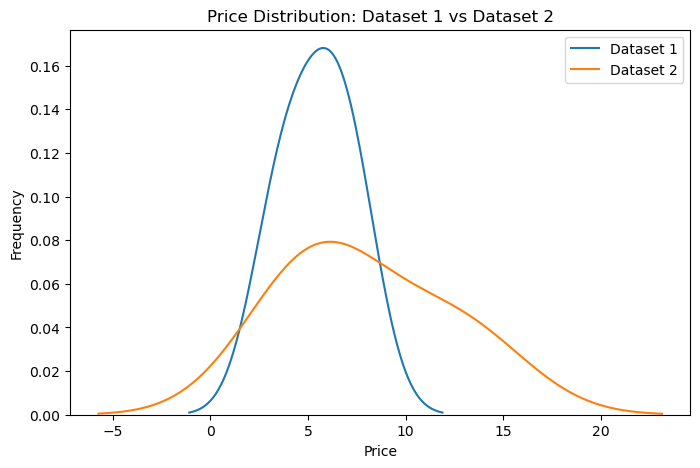

In [16]:

dataset_1 = pd.DataFrame({
    'Area': [1200, 1800, 1400],
    'BuiltIn': [1999, 2001, 2000],
    'Price': [3.5, 5.6, 7.3]
})

dataset_2 = pd.DataFrame({
    'Area': [2200, 800, 1100],
    'BuiltIn': [1989, 2018, 2005],
    'Price': [4.6, 6.5, 12.8]
})

import matplotlib.pyplot as plt
import seaborn as sns

sns.kdeplot(dataset_1['Price'], label='Dataset 1')
sns.kdeplot(dataset_2['Price'], label='Dataset 2')

plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Price Distribution: Dataset 1 vs Dataset 2')
plt.legend()
plt.show()

In [ ]:
# TODO-4.1: for each unique value of feature_col:
    #   1. get the subset of df where feature_col == value
    #   2. compute its entropy on target_col using entropy() from Part 3
    #   3. weight it by (size of subset / total) and add to weighted_entropy

In [17]:
def weighted_child_entropy(df, feature_col, target_col):
    '''
    Compute the weighted average entropy of the children created by
    splitting df on feature_col.
    '''
    total = len(df)
    weighted_entropy = 0.0
    for value in df[feature_col].unique():
        subset = df[df[feature_col] == value]
        child_entropy = entropy(subset[target_col])
        weight = len(subset) / total
        weighted_entropy += weight * child_entropy

    return weighted_entropy


def information_gain(df, feature_col, target_col):
    '''
    Compute Information Gain from splitting df on feature_col.
    '''
    parent_entropy = entropy(df[target_col])
    child_entropy = weighted_child_entropy(df, feature_col, target_col)
    # TODO: return IG = parent_entropy - child_entropy
    
    return parent_entropy - child_entropy


# ---- check against the worked example (do not edit) ----
ig_outlook = information_gain(play_tennis, 'Outlook', 'PlayTennis')
print(f"IG(Outlook)  = {ig_outlook:.2f}  (expected approx 0.25)")

IG(Outlook)  = 0.25  (expected approx 0.25)


In [ ]:
# TODO-4.1: compute Information Gain for the remaining columns and print them all
# TODO-4.1: print which column should be chosen as the ROOT NODE (highest IG)

In [18]:
ig_temp = information_gain(play_tennis, 'Temp', 'PlayTennis')
ig_humidity = information_gain(play_tennis, 'Humidity', 'PlayTennis')
ig_windy = information_gain(play_tennis, 'Windy', 'PlayTennis')

print(f"IG(Outlook)  = {ig_outlook:.3f}")
print(f"IG(Temp)     = {ig_temp:.3f}")
print(f"IG(Humidity) = {ig_humidity:.3f}")
print(f"IG(Windy)    = {ig_windy:.3f}")

ig_values = {
    'Outlook': ig_outlook,
    'Temp': ig_temp,
    'Humidity': ig_humidity,
    'Windy': ig_windy
}

root_node = max(ig_values, key=ig_values.get)
print(f"\nRoot Node = {root_node}")

IG(Outlook)  = 0.247
IG(Temp)     = 0.029
IG(Humidity) = 0.152
IG(Windy)    = 0.048

Root Node = Outlook
